# Olist: Impact of Late Delivery on Customer Reviews

This notebook analyses how late delivery affects review scores. The data comes from the `analytics_orders` table, which is created by the SQL pipeline (one row per delivered order).

## Importing Libraries

In [7]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [1]:
# Resolve the project root whether the notebook runs from the root or from notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DB_PATH = PROJECT_ROOT / "data" / "database" / "olist.db"

conn = sqlite3.connect(DB_PATH)
try:
    df = pd.read_sql_query("SELECT * FROM analytics_orders", conn)
finally:
    conn.close()

df["purchase_ts"] = pd.to_datetime(df["purchase_ts"])
print("Shape:", df.shape)
df.head()

Shape: (95824, 18)


,order_id,customer_unique_id,customer_state,purchase_ts,purchase_month,purchase_weekday,purchase_hour,estimated_delivery_days,item_count,distinct_product_count,seller_count,total_price,total_freight,freight_to_price_ratio,actual_delivery_days,delivery_delay_days,is_late,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,9,3,8,15.63,1,1,1,58.90,13.29,0.2256,7.61,-8.01,0,5
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26 10:53:06,4,3,10,18.55,1,1,1,239.90,19.93,0.0831,16.22,-2.33,0,4
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14 14:33:31,1,0,14,21.39,1,1,1,199.00,17.87,0.0898,7.95,-13.44,0,5
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08 10:00:35,8,3,10,11.58,1,1,1,12.99,12.79,0.9846,6.15,-5.44,0,4
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04 13:57:51,2,6,13,40.42,1,1,1,199.90,18.14,0.0907,25.11,-15.30,0,5


### Check for datatypes

In [13]:
df.dtypes

order_id                           object
customer_unique_id                 object
customer_state                     object
purchase_ts                datetime64[ns]
purchase_month                      int64
purchase_weekday                    int64
purchase_hour                       int64
estimated_delivery_days           float64
item_count                          int64
distinct_product_count              int64
seller_count                        int64
total_price                       float64
total_freight                     float64
freight_to_price_ratio            float64
actual_delivery_days              float64
delivery_delay_days               float64
is_late                             int64
review_score                        int64
delay_group                      category
purchase_year_month                object
dtype: object

### Check for missing values per Column

In [4]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
order_id                   0
customer_unique_id         0
customer_state             0
purchase_ts                0
purchase_month             0
purchase_weekday           0
purchase_hour              0
estimated_delivery_days    0
item_count                 0
distinct_product_count     0
seller_count               0
total_price                0
total_freight              0
freight_to_price_ratio     0
actual_delivery_days       0
delivery_delay_days        0
is_late                    0
review_score               0
dtype: int64


### Data description

In [6]:
df.describe().round(2)

,purchase_ts,purchase_month,purchase_weekday,purchase_hour,estimated_delivery_days,item_count,distinct_product_count,seller_count,total_price,total_freight,freight_to_price_ratio,actual_delivery_days,delivery_delay_days,is_late,review_score
count,95824,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00,95824.00
mean,2018-01-02 02:54:30.831336192,6.03,2.91,14.77,23.73,1.14,1.04,1.01,136.80,22.76,0.31,12.52,-11.22,0.08,4.16
min,2016-09-15 12:16:38,1.00,0.00,0.00,2.01,1.00,1.00,1.00,0.85,0.00,0.00,0.53,-146.02,0.00,1.00
25%,2017-09-14 10:23:40.500000,3.00,1.00,11.00,18.33,1.00,1.00,1.00,45.90,13.84,0.13,6.76,-16.25,0.00,4.00
50%,2018-01-20 23:35:09.500000,6.00,3.00,15.00,23.23,1.00,1.00,1.00,86.25,17.16,0.22,10.21,-11.97,0.00,5.00
75%,2018-05-05 23:59:13,8.00,5.00,19.00,28.41,1.00,1.00,1.00,149.90,23.99,0.38,15.66,-6.41,0.00,5.00
max,2018-08-29 15:00:37,12.00,6.00,23.00,155.14,21.00,8.00,5.00,13440.00,1794.96,21.45,208.35,188.98,1.00,5.00
std,NaN,3.23,1.89,5.33,8.76,0.53,0.23,0.12,207.79,21.52,0.31,9.46,10.11,0.27,1.28


## Chart 1: Review Score Distribution for On-Time vs Late Orders

The chart below compares how review scores (1 to 5) are distributed among on-time and late orders. Percentages are used instead of counts because there are far fewer late orders than on-time orders.

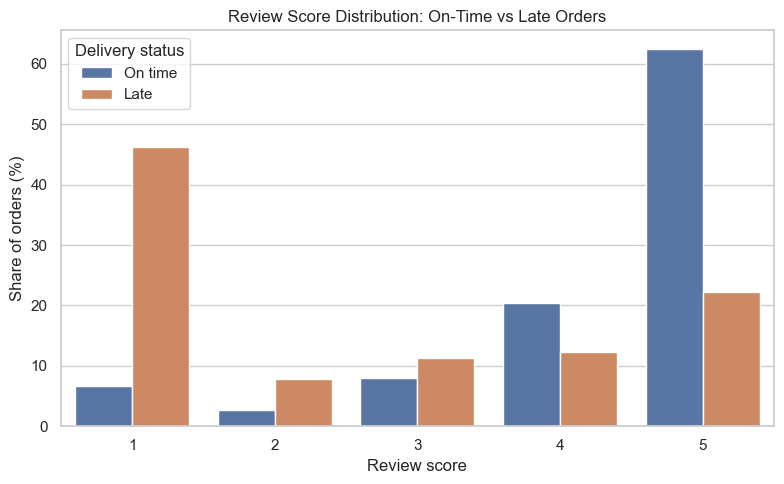

delivery_status,Late,On time
review_score,,
1,46.2,6.6
2,7.9,2.6
3,11.4,8.0
4,12.3,20.4
5,22.2,62.4


In [8]:
sns.set_theme(style="whitegrid")

# Share of each review score within on-time and late orders (in percent).
distribution = (df.groupby("is_late")["review_score"].value_counts(normalize=True).mul(100).rename("percent").reset_index())
distribution["delivery_status"] = distribution["is_late"].map({0: "On time", 1: "Late"})

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=distribution,x="review_score",y="percent",hue="delivery_status",hue_order=["On time", "Late"],ax=ax,)
ax.set_title("Review Score Distribution: On-Time vs Late Orders")
ax.set_xlabel("Review score")
ax.set_ylabel("Share of orders (%)")
ax.legend(title="Delivery status")
plt.tight_layout()
plt.show()

distribution.pivot(
    index="review_score", columns="delivery_status", values="percent"
).round(1)

**Observation**

- Late orders receive a score of 1 far more often: 46.2% of late orders versus 6.6% of on-time orders, about seven times higher.
- The most common score for on-time orders is 5 (62.4%), while only 22.2% of late orders receive a 5.
- Scores of 4 or 5 account for 82.8% of on-time orders but only 34.5% of late orders.
- Scores of 1 or 2 account for 54.1% of late orders versus 9.2% of on-time orders.
- This shows a strong association between late delivery and low review scores. It does not prove that lateness is the only cause, since other factors may also affect reviews.

## Chart 2: Average Review Score by Delivery Delay

Orders are grouped by how many days they arrived before or after the estimated delivery date. The chart shows the average review score for each group, so we can see how the review score changes as the delay grows.

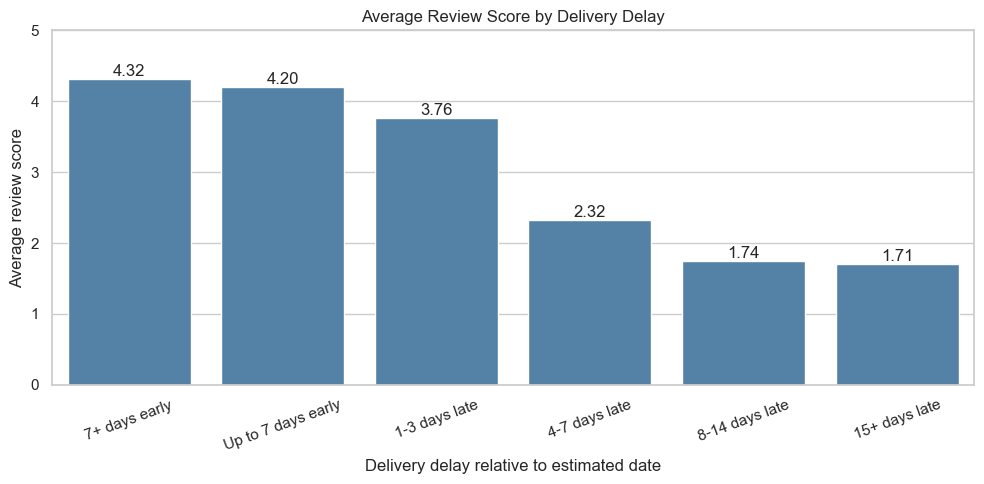

,delay_group,orders,avg_review_score
0,7+ days early,70946,4.32
1,Up to 7 days early,17223,4.20
2,1-3 days late,2634,3.76
3,4-7 days late,1773,2.32
4,8-14 days late,1744,1.74
5,15+ days late,1504,1.71


In [9]:
# Group orders by delivery delay (negative values mean earlier than estimated).
delay_bins = [-float("inf"), -7, 0, 3, 7, 14, float("inf")]
delay_labels = [
    "7+ days early","Up to 7 days early","1-3 days late","4-7 days late","8-14 days late","15+ days late",
]
df["delay_group"] = pd.cut(df["delivery_delay_days"], bins=delay_bins, labels=delay_labels)

summary = (df.groupby("delay_group", observed=True).agg(orders=("order_id", "count"), avg_review_score=("review_score", "mean")).round(2).reset_index())

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=summary,x="delay_group",y="avg_review_score",color="steelblue",ax=ax,)
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_ylim(0, 5)
ax.set_title("Average Review Score by Delivery Delay")
ax.set_xlabel("Delivery delay relative to estimated date")
ax.set_ylabel("Average review score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

summary

**Observation**

- Orders delivered earlier than the estimated date receive high scores: 4.32 for orders more than 7 days early and 4.20 for orders up to 7 days early.
- A short delay already lowers satisfaction. Orders 1-3 days late average 3.76, which is about 0.4 points below the on-time groups.
- The score falls sharply once the delay passes three days: orders 4-7 days late average 2.32, and orders 8-14 days late average 1.74.
- The decline flattens after about a week. Orders 15+ days late average 1.71, only slightly below the 8-14 day group, so scores seem to reach a floor.
- Most late orders are seriously late: 4 or more days late accounts for about 66% of all late orders (5,021 of 7,655).
- Customers seem to tolerate small delays, but satisfaction drops quickly after the first few days. Reducing long delays, or setting more realistic estimated delivery dates, would likely protect review scores the most.

## Chart 3: Late Delivery Rate by Customer State

The chart shows the percentage of orders delivered late in each customer state. Only states with at least 500 orders are included, because percentages from very small samples are unreliable. The dashed line marks the overall late rate.

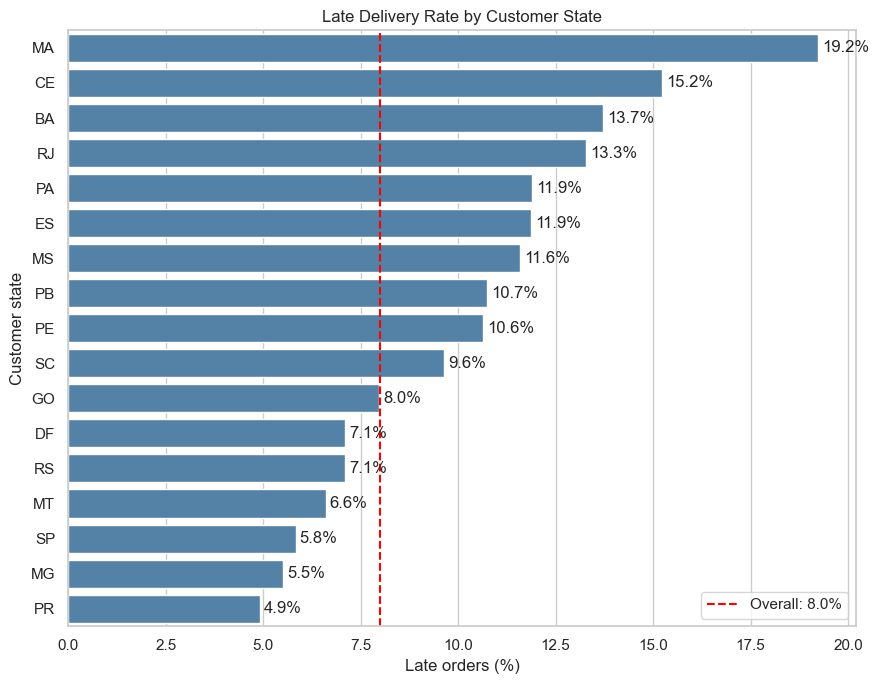

,customer_state,orders,late_orders,late_percent
0,MA,712,137,19.24
1,CE,1273,194,15.24
2,BA,3229,443,13.72
3,RJ,12211,1623,13.29
4,PA,933,111,11.90
5,ES,1969,234,11.88
6,MS,699,81,11.59
7,PB,512,55,10.74
8,PE,1579,168,10.64
9,SC,3519,339,9.63


In [10]:
MIN_ORDERS = 500

state_summary = (
    df.groupby("customer_state").agg(orders=("order_id", "count"), late_orders=("is_late", "sum")).reset_index())
state_summary["late_percent"] = (100 * state_summary["late_orders"] / state_summary["orders"]).round(2)
state_summary = (
    state_summary[state_summary["orders"] >= MIN_ORDERS].sort_values("late_percent", ascending=False).reset_index(drop=True))
overall_late_percent = 100 * df["is_late"].mean()

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot( data=state_summary,x="late_percent", y="customer_state",color="steelblue",ax=ax,)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.axvline(
    overall_late_percent,color="red",linestyle="--",label=f"Overall: {overall_late_percent:.1f}%",)
ax.set_title("Late Delivery Rate by Customer State")
ax.set_xlabel("Late orders (%)")
ax.set_ylabel("Customer state")
ax.legend()
plt.tight_layout()
plt.show()

state_summary

**Observation**

- Late delivery rates differ widely by state. Maranhão (MA) has the highest rate at 19.24%, about 2.4 times the overall rate of 7.99%, followed by Ceará (CE) at 15.24% and Bahia (BA) at 13.72%.
- Ten of the 17 states shown are above the overall rate: MA, CE, BA, RJ, PA, ES, MS, PB, PE and SC. Several of them are in Brazil's northeast (MA, CE, BA, PB, PE).
- The lowest rates are in Paraná (PR) at 4.92%, Minas Gerais (MG) at 5.51% and São Paulo (SP) at 5.83%.
- Rio de Janeiro (RJ) stands out because of its volume. At 13.29% it has the fourth highest rate and, with 1,623 late orders, accounts for about 21% of all late orders while making up about 13% of all orders.
- São Paulo has by far the most orders (40,266) and still keeps a low late rate, which suggests that deliveries within and near the main seller region are more reliable.
- The differences likely reflect distance and local logistics, which are not measured directly here. Customer state is therefore a useful candidate feature for the late delivery model.

## Chart 4: Monthly Late Delivery Rate

The chart shows the percentage of orders delivered late for each purchase month. Only months with at least 500 orders are included, because percentages from very small samples are unreliable. The dashed line marks the overall late rate.

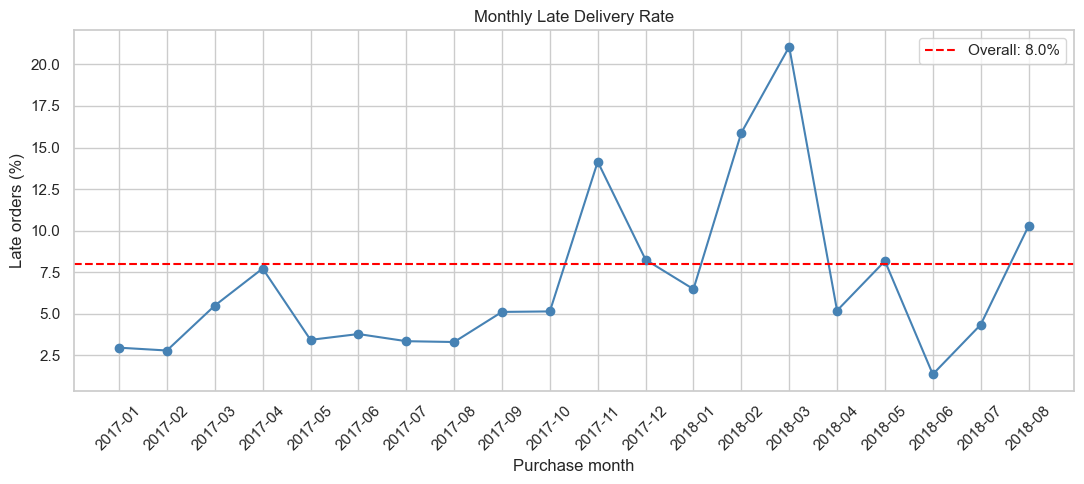

,purchase_year_month,orders,late_orders,late_percent
0,2017-01,741,22,2.97
1,2017-02,1643,46,2.80
2,2017-03,2527,139,5.50
3,2017-04,2290,177,7.73
4,2017-05,3517,121,3.44
5,2017-06,3111,118,3.79
6,2017-07,3842,129,3.36
7,2017-08,4165,138,3.31
8,2017-09,4118,211,5.12
9,2017-10,4446,229,5.15


In [11]:
MIN_MONTHLY_ORDERS = 500

df["purchase_year_month"] = df["purchase_ts"].dt.strftime("%Y-%m")

monthly_summary = (df.groupby("purchase_year_month").agg(orders=("order_id", "count"), late_orders=("is_late", "sum")).reset_index())
monthly_summary["late_percent"] = (100 * monthly_summary["late_orders"] / monthly_summary["orders"]).round(2)

monthly_summary = monthly_summary[monthly_summary["orders"] >= MIN_MONTHLY_ORDERS].reset_index(drop=True)
overall_late_percent = 100 * df["is_late"].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_summary["purchase_year_month"],monthly_summary["late_percent"],marker="o",color="steelblue",)
ax.axhline(overall_late_percent,color="red",linestyle="--",label=f"Overall: {overall_late_percent:.1f}%",)

ax.set_title("Monthly Late Delivery Rate")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Late orders (%)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly_summary

**Observation**

- The late delivery rate is low and stable through most of 2017, between about 2.8% and 7.7% per month, but it spikes sharply in a few later months.
- November 2017 reaches 14.15%. Order volume that month jumps to 7,237 from 4,446 in October (about 63% more), which is consistent with the Black Friday sales peak overloading deliveries. The rate falls back to 8.26% in December.
- The two highest rates come in February 2018 (15.89%) and March 2018 (21.06%). March 2018 is the worst month, with 1,463 late orders, about 19% of all late orders in the dataset.
- These two months cannot be explained by volume alone: order counts in February and March 2018 (6,507 and 6,948) are close to January 2018 (7,013), which had a much lower rate of 6.49%.
- November 2017, February 2018 and March 2018 together account for about 46% of all late orders while making up only about 22% of all orders.
- The rate drops to 5.20% in April 2018 and to the lowest value, 1.37%, in June 2018, then rises again to 10.28% in August 2018.
- Late deliveries are therefore concentrated in specific periods rather than spread evenly. The data does not show the cause of the February-March 2018 spike, so it should be treated as an unexplained period.

## Conclusion

**Question:** How much does late delivery hurt customer reviews, and where and when do late deliveries happen?

**Scope:** 95,824 delivered orders that have at least one item and a review. An order is late if it arrived after the estimated delivery date. The overall late rate is 7.99%.

**Key findings**

1. **Late delivery strongly lowers review scores.** On-time orders average 4.29, while late orders average 2.57, a gap of about 1.7 points. 46.2% of late orders receive a score of 1, compared with 6.6% of on-time orders.
2. **The damage grows with the length of the delay.** Orders 1-3 days late average 3.76, orders 4-7 days late average 2.32, and orders 8 or more days late average about 1.7. Scores fall quickly in the first week of delay and then flatten out.
3. **Late deliveries are concentrated in certain states.** Maranhão has the highest late rate (19.24%), and several northeastern states are well above the overall rate. São Paulo, Minas Gerais and Paraná have the lowest rates (4.92% to 5.83%).
4. **Late deliveries are concentrated in certain periods.** The late rate peaks in November 2017 (14.15%, during a surge in order volume), February 2018 (15.89%) and March 2018 (21.06%). These three months account for about 46% of all late orders but only about 22% of all orders.

**Limitations**

- The results show an association between late delivery and low review scores, not proof that lateness is the only cause of low scores.
- The reason for the February-March 2018 spike cannot be determined from this data.
- Orders without items or without a review are excluded, so the results describe reviewed, delivered orders only.